In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-09-20 18:54:31--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 

200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv.5’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.004s  

2026-09-20 18:54:31 (138 MB/s) - ‘car_fuel_efficiency_2026.csv.5’ saved [635180/635180]



In [25]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [26]:
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

df = df[columns]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


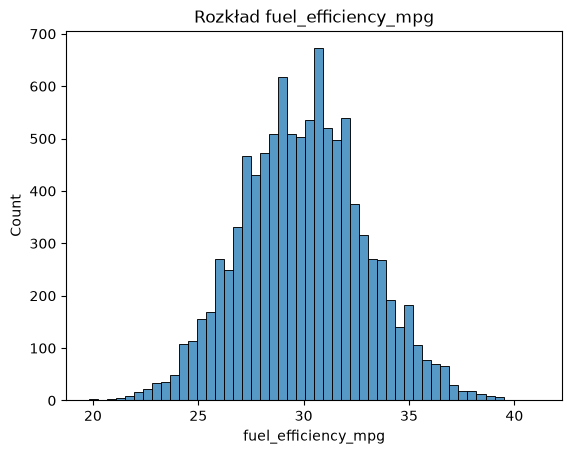

In [27]:
sns.histplot(df['fuel_efficiency_mpg'], bins=50)
plt.title('Rozkład fuel_efficiency_mpg')
plt.show()

In [28]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [29]:
df['horsepower'].median()

np.float64(254.0)

In [30]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [31]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

def prepare_X(df_subset, fill_value):
    df_num = df_subset.copy()
    df_num = df_num.fillna(fill_value)
    return df_num.values

In [32]:
# Opcja 1 - wypełnienie braków zerami

X_train_0 = prepare_X(df_train, 0)
w0_zero, w_zero = train_linear_regression(X_train_0, y_train)

X_val_0 = prepare_X(df_val, 0)
y_pred_0 = w0_zero + X_val_0.dot(w_zero)
score_0 = round(rmse(y_val, y_pred_0), 3)



In [33]:
# Opcja 2: Wypełnienie braków średnią

mean_val = df_train['horsepower'].mean()

X_train_mean = prepare_X(df_train, mean_val)
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

X_val_mean = prepare_X(df_val, mean_val)
y_pred_mean = w0_mean + X_val_mean.dot(w_mean)
score_mean = round(rmse(y_val, y_pred_mean), 3)

In [34]:
print(f"RMSE (z zerem): {score_0}")
print(f"RMSE (ze średnią): {score_mean}")

RMSE (z zerem): 2.205
RMSE (ze średnią): 2.202


In [35]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

X_train = prepare_X(df_train, fill_value=0)
X_val = prepare_X(df_val, fill_value=0)

r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_values:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    score = round(rmse(y_val, y_pred), 4)
    print(f"r: {r:6} | RMSE: {score}")

r:      0 | RMSE: 2.2053
r:   0.01 | RMSE: 2.2058
r:    0.1 | RMSE: 2.2241
r:      1 | RMSE: 2.3492
r:      5 | RMSE: 2.4094
r:     10 | RMSE: 2.4195
r:    100 | RMSE: 2.4292


In [36]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []

n = len(df_clean)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

for s in seeds:
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_shuffled = df_clean.iloc[idx].reset_index(drop=True)

    df_train = df_shuffled.iloc[:n_train].copy()
    df_val = df_shuffled.iloc[n_train:n_train + n_val].copy()

    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values

    features_train = df_train.drop(columns=['fuel_efficiency_mpg'])
    features_val = df_val.drop(columns=['fuel_efficiency_mpg'])

    X_train = features_train.fillna(0).values
    X_val = features_val.fillna(0).values

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    scores.append(score)

std_val = np.std(scores)
print("RMSE per seed:", [round(s, 4) for s in scores])
print("Std bez zaokrąglenia:", std_val)
print("Odpowiedź (round(std, 3)):", round(std_val, 3))

RMSE per seed: [np.float64(2.2392), np.float64(2.2021), np.float64(2.1634), np.float64(2.2044), np.float64(2.2019), np.float64(2.2458), np.float64(2.2697), np.float64(2.1908), np.float64(2.2166), np.float64(2.207)]
Std bez zaokrąglenia: 0.028781274078187116
Odpowiedź (round(std, 3)): 0.029


In [37]:
np.random.seed(9)

n = len(df_clean)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df_clean.iloc[idx].reset_index(drop=True)

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train + n_val].copy()
df_test = df_shuffled.iloc[n_train + n_val:].copy()

df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

y_full_train = df_full_train['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

features_full_train = df_full_train.drop(columns=['fuel_efficiency_mpg'])
features_test = df_test.drop(columns=['fuel_efficiency_mpg'])

X_full_train = features_full_train.fillna(0).values
X_test = features_test.fillna(0).values

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

y_pred_test = w0 + X_test.dot(w)
test_score = rmse(y_test, y_pred_test)

print("Pełny wynik RMSE:", test_score)
print("Zaokrąglenie do 3 miejsc:", round(test_score, 3))
print("Zaokrąglenie do 2 miejsc:", round(test_score, 2))

Pełny wynik RMSE: 2.2358277471917636
Zaokrąglenie do 3 miejsc: 2.236
Zaokrąglenie do 2 miejsc: 2.24
